In [10]:
import pandas as pd
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
root = Path.cwd()

In [6]:
### rmse vs. scale plot


features = ['three_seasons','summer_fall','growing_season']

df_plot = []
for f in features:
    df = pd.read_csv(root / 'model_outputs' / 'resamp' / f'nyc21_canopy_from_nyc21_{f}_OOF_model.csv')
    old_cols = df.columns
    df.columns = [f'{c}_{f}' for c in old_cols]
    df_plot.append(df)
df_plot = pd.concat(df_plot,axis=1)



In [19]:
for k in list(styles.keys()):
    print(styles[k]['color'])
    print(styles[k]['desc'])
   

#285A48
Three Seasons Model (spring, summer, fall)
#3B9797
Two Seasons Model (summer, fall)
#8BBB92
Growing Season Model


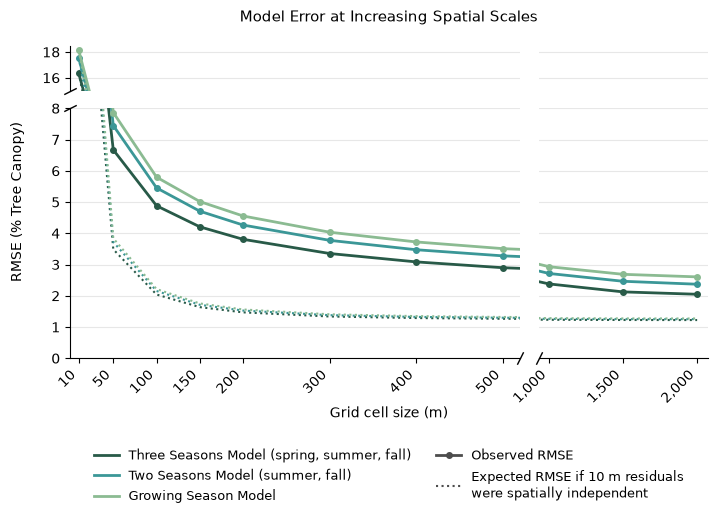

In [41]:
c1 = '#285A48'
c2 = '#8BBB92'
c3 = '#3B9797'

styles = {'three_seasons': dict(desc='Three Seasons Model (spring, summer, fall)',color=c1), 'summer_fall': dict(desc='Two Seasons Model (summer, fall)',color=c3), 'growing_season': dict(desc='Growing Season Model',color=c2)}

X_SEGMENTS = [(0, 520), (930, 2070)]   # x range of each segment
X_WIDTHS = [8, 3]                      # relative segment widths
Y_BREAK = (8, 15)                      # (top of lower part, bottom of upper part); None = no y break
Y_HEIGHTS = [0.8, 4.5]                 # relative heights of the upper and lower parts
Y_STEP = 1                             # y tick spacing below the break
MARK = dict(markersize=9, ls='none', color='k', mew=1, clip_on=False)


def broken_axes(fig, df, x_col, models, ytop):
    """One panel split into x segments (and two y parts if Y_BREAK is set). Every sub-axis draws all
    lines, clipped to its own range, so each line runs across the gaps."""
    if Y_BREAK:
        ylims, heights = [(Y_BREAK[1], ytop), (0, Y_BREAK[0])], Y_HEIGHTS
    else:
        ylims, heights = [(0, ytop)], [1]
    nr, nc = len(ylims), len(X_SEGMENTS)
    axs = fig.subplots(nr, nc, squeeze=False,
                       gridspec_kw=dict(height_ratios=heights, width_ratios=X_WIDTHS, hspace=0.12, wspace=0.06))
    x = df[x_col]
    for r in range(nr):
        for c in range(nc):
            ax = axs[r, c]
            for k in list(models.keys()):
                color = models[k]['color']
                ax.plot(x, df[f'rmse_{k}'], color=color, lw=2, marker='o', ms=4)
                ax.plot(x, df[f'rmse_indep_{k}'], color=color, lw=1.5, ls=':')
            ax.set_xlim(X_SEGMENTS[c]); ax.set_ylim(ylims[r])
            ax.grid(axis='y', alpha=0.3)

            for side in ('top', 'right'):
                ax.spines[side].set_visible(False)
            if r < nr - 1:
                ax.spines['bottom'].set_visible(False)
                ax.tick_params(bottom=False, labelbottom=False)
            if c > 0:
                ax.spines['left'].set_visible(False)
                ax.tick_params(left=False, labelleft=False)

            lo, hi = X_SEGMENTS[c]
            t = [v for v in x if lo <= v <= hi]
            ax.set_xticks(t)
            ax.set_xticklabels([f'{int(v):,}' for v in t], rotation=45, ha='right')

            if r == nr - 1:                                   # '/' marks on the x axis line at the x break
                if c < nc - 1:
                    ax.plot([1], [0], transform=ax.transAxes, marker=[(-0.5, -1), (0.5, 1)], **MARK)
                if c > 0:
                    ax.plot([0], [0], transform=ax.transAxes, marker=[(-0.5, -1), (0.5, 1)], **MARK)
            if Y_BREAK and c == 0:                            # ... and on the y axis line at the y break
                ax.plot([0], [0 if r == 0 else 1], transform=ax.transAxes,
                        marker=[(-1, -0.5), (1, 0.5)], **MARK)

    for ax in axs[-1]:
        ax.yaxis.set_major_locator(plt.MultipleLocator(Y_STEP))
    if Y_BREAK:
        for ax in axs[0]:
            ax.yaxis.set_major_locator(plt.MaxNLocator(2, integer=True))
    return axs


def plot_rmse_vs_scale(df, models=styles, fname=None):
    x_col = f'res_{next(iter(models))}'
    ytop = max(float(df[[f'rmse_{m}', f'rmse_indep_{m}']].max().max()) for m in models) + 0.3

    fig = plt.figure(figsize=(7.5, 5.2))
    left, right, bottom, top = 0.12, 0.97, 0.30, 0.90
    broken_axes(fig, df, x_col, models, ytop)
    fig.subplots_adjust(left=left, right=right, bottom=bottom, top=top)
    mid = (left + right) / 2                                     # centre text over the plotting area
    fig.suptitle('Model Error at Increasing Spatial Scales', fontsize=11, x=mid, y=0.97)
    fig.supxlabel('Grid cell size (m)', fontsize=10, x=mid, y=0.18)
    fig.supylabel('RMSE (% Tree Canopy)', fontsize=10, x=0.04,y=0.6)

    # legend: colour = model, line style = observed vs expected
    handles = [Line2D([], [], color=models[l]['color'], lw=2, label=models[l]['desc']) for l in list(models.keys())] + [
        Line2D([], [], color='0.3', lw=2, marker='o', ms=4, label='Observed RMSE'),
        Line2D([], [], color='0.3', lw=1.5, ls=':',
               label='Expected RMSE if 10 m residuals\nwere spatially independent')]
    fig.legend(handles=handles, loc='lower center', ncol=2, frameon=False, fontsize=9, bbox_to_anchor=(mid, 0.0))
    if fname:
        plt.savefig(fname, dpi=300, bbox_inches='tight')
    plt.show()


plot_rmse_vs_scale(df_plot, fname='rmse_vs_scale_models.png')